# SQDMetal two-transmon example — two pocket transmons joined by a straight coupler (Quantcore PDK rebuild)

**What the chip is.** sqdlab SQDMetal's `doc-sphinx/source/examples/two_transmon.ipynb`
(<https://github.com/sqdlab/SQDMetal>, **Apache-2.0**; spec `docs/designs/sqdmetal/two_transmon.md`): a Quantum
Metal design for an SQDMetal Palace eigenmode run (2 modes from 5 GHz, silicon 500 µm), with no stored outputs.
Two floating `TransmonPocket`s 1 mm apart; their facing connection pads are joined by a straight CPW
(`RouteStraight`) — a direct capacitive link with no resonator, a minimal two-qubit eigenmode / EPR test. There are
no launchers or pads (an eigenmode model only).

This notebook **rebuilds** it with our components, routes, netlist and LOM on the Quantcore PDK (not a replica);
we distribute the rebuild under GPL-3.0.

| topic | SQDMetal source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | Metal chip 2.2 × 1.8 mm centred on (0.5, 0) mm | the 7.5 × 7.5 mm Quantcore die with its frame (dicing L's, alignment grids, boundary, device ID "SQD-2T"); the source area sits in its centre, so every coordinate is the source's + (600, 900) µm |
| pads | none (Palace ports on the junctions) | none: nothing to put on the pad rule (`frame.pad_edge`, 100 µm) |
| substrate | silicon, 500 µm | sapphire 650 µm, εr 10.25 |
| junctions | Palace lumped L_J 13 / 9 nH, C_J 0 | Quantcore trilayer junctions at the two ends of the 40–50 kΩ window: Q1 50 kΩ (L_J ≈ 7.5 nH), Q2 40 kΩ (≈ 6.0 nH) — the source's detuning order |
| cheese | none (the source only meshes the design for Palace: `eigen_sim.add_ground_plane()`, no holes) | the PDK band (chip `cheese` `"auto"`): 5 µm squares, 20 µm gaps, 3 rows round the 3/0 keep-outs, at least 4 µm clear of 3/0 |
| components, positions | `TransmonPocket` × 2, `RouteStraight` | kept: Metal components through the `metal:` wrapper, the source options and positions |
| placement | — | centred in the die (checked: no shift) |

**Not reproduced:** the `hfss_wire_bonds` flag (an HFSS rendering option).

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die, the two pocket transmons (the chip has no pads and no readout), the straight coupler between them, and then the whole chip (the sim group, the centring check, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `two_transmon.v1.ipynb`; both save the same `two_transmon.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/two_transmon/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.layouts.registry import trilayer_junction

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs") / "sqdmetal"        # design JSON + final snapshots
STEPS = Path("build/snapshots") / "two_transmon"       # step-by-step snapshots (build/ is not kept in the repo)
X0, Y0 = 600, 900                                # Metal's chip is centred on (0.5, 0) mm

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and every FEM export, the frame and the pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**The junctions from the PDK rule.** `trilayer_junction("metal:TransmonPocket", lj_nH=...)` gives the cell
parameters of a Quantcore trilayer junction (`junction_type` + `junction_params`) and the drawn junction's L_J /
C_J for the LOM. The source detunes the pair with its Palace junctions (13 / 9 nH, a ratio of 1.44, wider than the
window's 1.25); the rebuild keeps that order at the two ends of the 40–50 kΩ window: Q1 R_n 50 kΩ (L_J ≈ 7.5 nH,
C_J ≈ 13.5 fF), Q2 40 kΩ (≈ 6.0 nH, ≈ 16.8 fF). Expected f_q ≈ 7.0 / 7.8 GHz (the source's junctions gave
5.9 / 7.2 GHz on this layout).

In [5]:
from quantcore_circuits.circuit.bridges import lj_from_rn
JJP_Q1, JJ_Q1 = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(50e3))   # R_n 50 kΩ
JJP_Q2, JJ_Q2 = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(40e3))   # R_n 40 kΩ
print("Q1", JJP_Q1, JJ_Q1)
print("Q2", JJP_Q2, JJ_Q2)

Q1 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 7.482691894823213}} {'Lj_nH': 7.4827, 'Cj_fF': 13.5}
Q2 {'junction_type': 'Quantcore Junction', 'junction_params': {'lj_nH': 5.986153515858571}} {'Lj_nH': 6.0129, 'Cj_fF': 16.8}


# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand, segment by segment; this one is the smallest kind of
two-qubit test, so several segments are empty (one sentence each): no pads, no readout, no control lines. Each
segment with something in it is one cell with one picture of the chip so far (live, KLayout redraws after every
cell). The coupler joins the two qubits' pads, so it comes after them.

| segment | what is placed here |
|---|---|
| 1 | the 7.5 × 7.5 mm Quantcore die with its frame (device ID SQD-2T) |
| 2 | bond pads: none (an eigenmode model: its only ports are the junctions) |
| 3 | readout line: none |
| 4 | the two `TransmonPocket`s with their trilayer junctions (Q1 at R_n 50 kΩ, Q2 at 40 kΩ) |
| 5 | readout resonators: none |
| 6 | the coupling: one straight CPW between the qubits' facing connection pads |
| 7 | the control routing: none |
| 8 | the whole chip: the sim group, the centring check, save |

## Design 1 · The die and its frame

`Designer(name, box=...)` opens the die: the 7.5 × 7.5 mm Quantcore die placed so that the source's 2.2 × 1.8 mm
area sits in its centre. The PDK frame is drawn on it: L dicing markers (1000/0) and a 3 × 3 alignment grid
(1001/0) in each corner area, the chip boundary (100/0) and the device ID `name_chip` on a free edge. The chip
`cheese` stays `"auto"`: the source has no cheese, so the build draws the PDK band once there is metal to band.

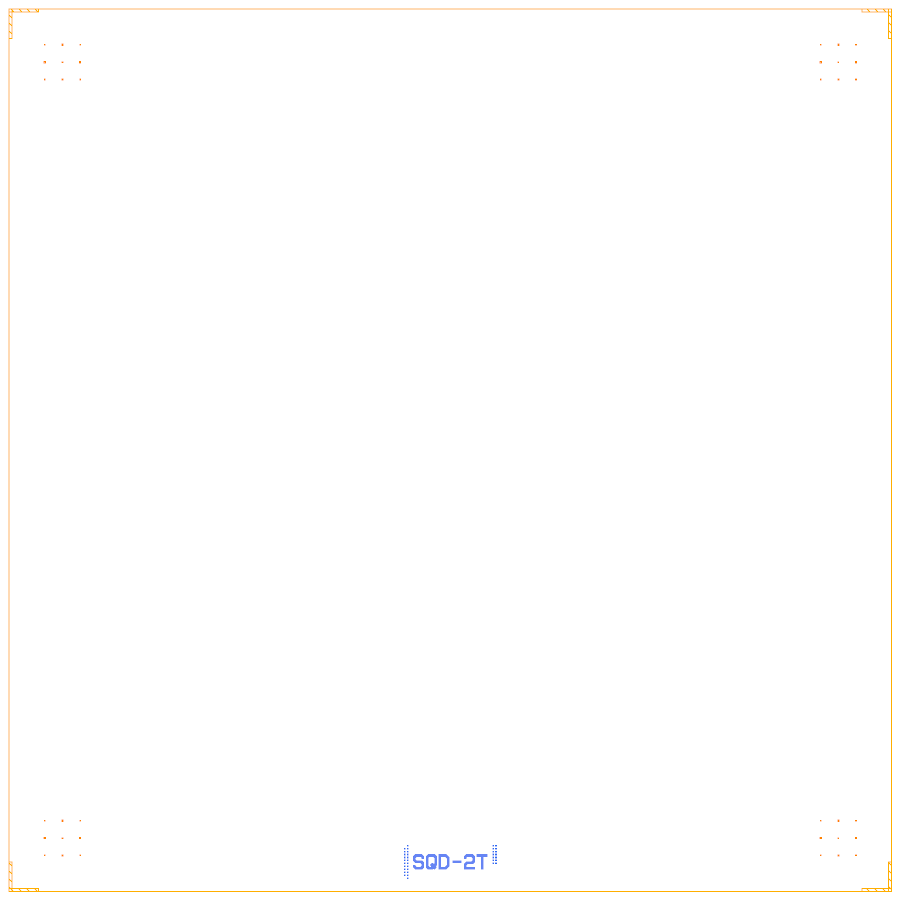

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/two_transmon/s1_die.png')

In [6]:
d = Designer("two_transmon", box=(-2650, -2850, 4850, 4650), chip={"name_chip": "SQD-2T"}, live=LIVE)
layout_step(d, STEPS / "s1_die.png", size=(900, 900), width=360)

## Design 2 · Bond pads: none on this chip

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge
(`d.add(..., edge="auto")`). The source is a Palace eigenmode model with no pads or launchers — its only ports are
the junctions — so there is nothing to place here.

## Design 3 · Readout line: none

No feedline and no readout: the source measures the two qubits' modes in an eigenmode run, not through a line.

## Design 4 · Qubit placement: two pocket transmons

Two Quantum Metal `TransmonPocket`s through the `metal:` wrapper (the Metal options are the cell parameters; bare
numbers on length options are µm): `pad_width` 425 µm, `pocket_height` 650 µm, the other options Metal's
defaults (pads 90 µm high, 30 µm apart, 650 µm pocket). Each has one `readout` connection pad, 200 µm wide, at
the top corner facing the other qubit (`loc_W` ±1, `loc_H` +1). The wrapper draws the Quantcore trilayer junction
across the pad gap (`junction_type` from the junction cell above), and its ports are Metal's pin names (`readout`) plus the
junction attachment points `squid_a` / `squid_b`.

The first picture is the whole die, the second zooms on the pair.

<metal:TransmonPocket Q1 ports=['readout', 'squid_a', 'squid_b']>


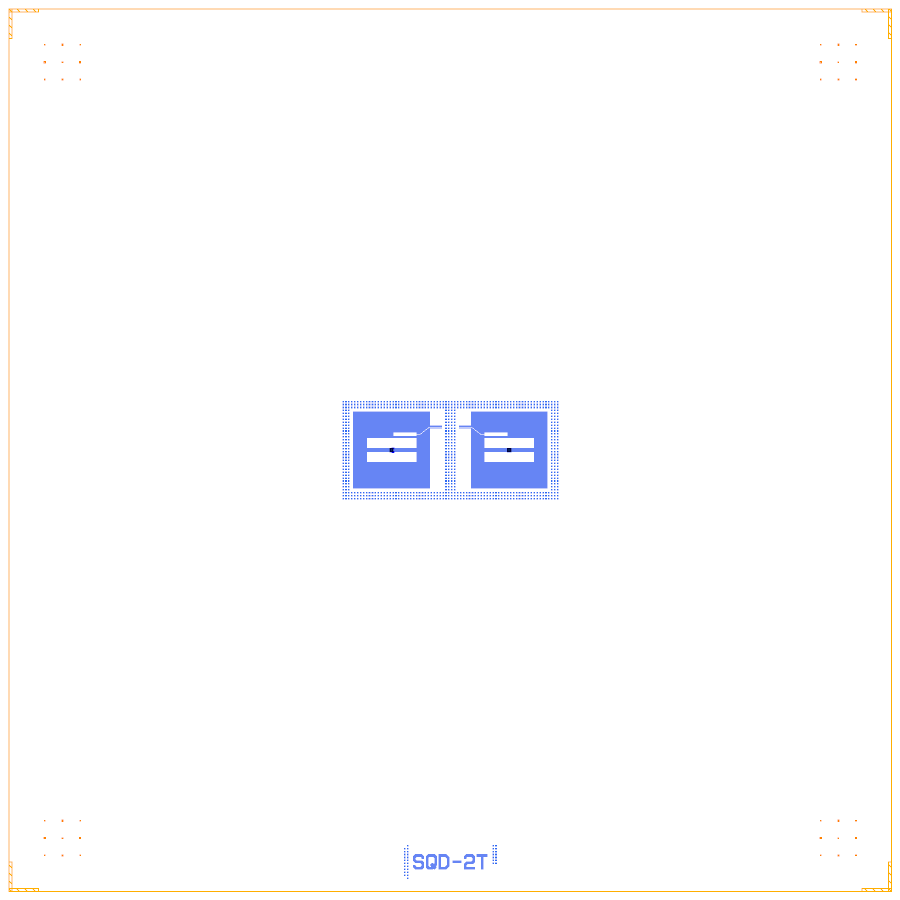

**On the chip so far:** 0 pads · 2 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `Q1`, `Q2`.

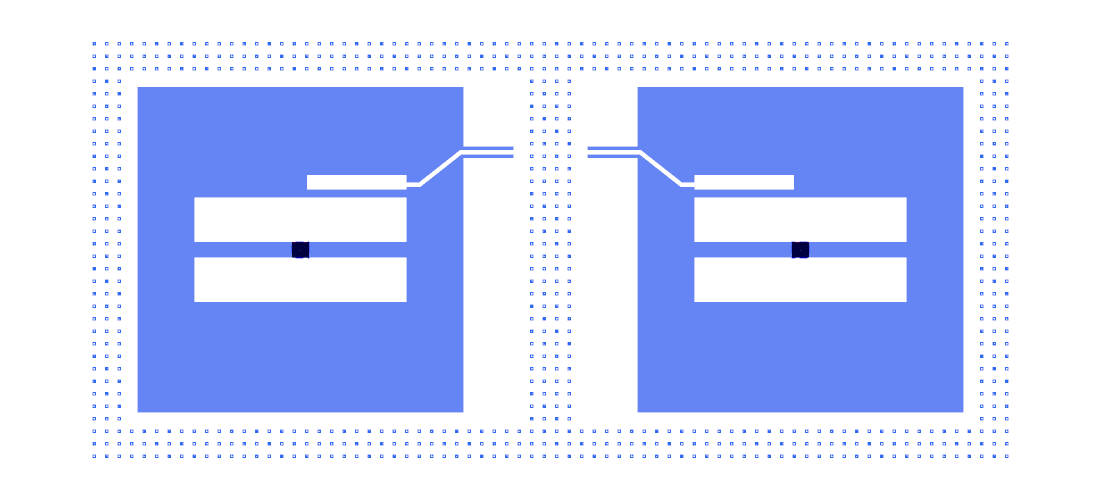

In [7]:
POCKET = dict(pad_width=425, pocket_height=650)
with d.batch():
    q1 = d.add("Q1", "metal:TransmonPocket", at=(X0, Y0), junction=JJ_Q1, **JJP_Q1,
               connection_pads={"readout": {"loc_W": 1, "loc_H": 1, "pad_width": 200}}, **POCKET)
    q2 = d.add("Q2", "metal:TransmonPocket", at=(X0 + 1000, Y0), junction=JJ_Q2, **JJP_Q2,
               connection_pads={"readout": {"loc_W": -1, "loc_H": 1, "pad_width": 200}}, **POCKET)
print(q1)
layout_step(d, STEPS / "s4_qubits.png", size=(900, 900), width=360)
snap(d, STEPS / "2_components.png", box=(X0 - 600, Y0 - 500, X0 + 1600, Y0 + 500), size=(1100, 500), width=520);

## Design 5 · Readout resonators: none

## Design 6 · Coupling: the straight coupler

The qubits couple directly: one straight CPW `COUPLER` between the two `readout` pins (10/6 µm, the PDK default; the
source's `RouteStraight`), so Q1 and Q2 see each other through the series capacitance pad → line → pad, with no
resonator in between. `r=20` only sets the bend radius of the port stubs, since the pins are 150 µm apart on one
line. The picture zooms on the pair.

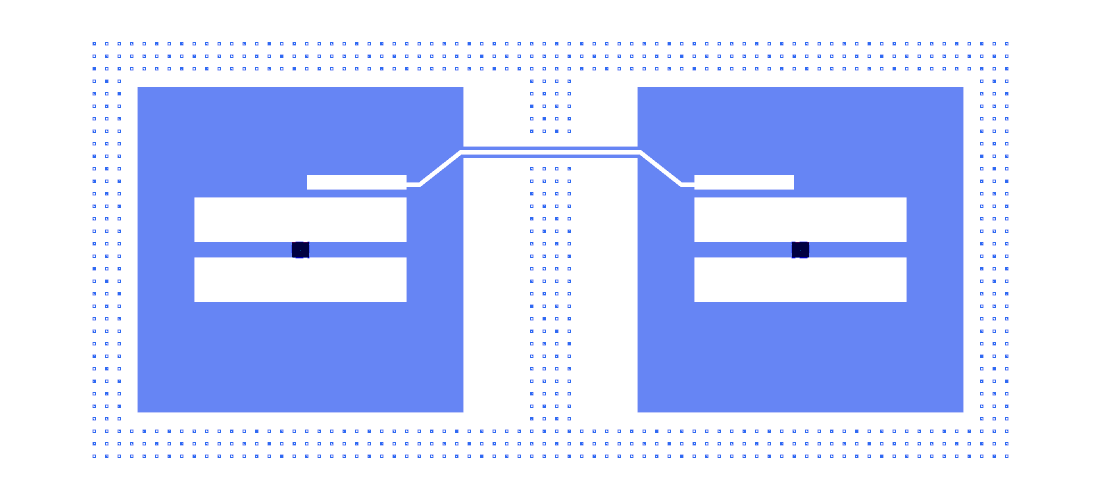

**On the chip so far:** 0 pads · 2 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `COUPLER`.

coupler 150.0 µm


In [8]:
d.route("COUPLER", q1.readout, q2.readout, r=20)    # straight; r only sets the port stubs
layout_step(d, STEPS / "s6_coupler.png", box=(X0 - 600, Y0 - 500, X0 + 1600, Y0 + 500), size=(1100, 500), width=520)
print("coupler", round(d.result.route_lengths()["COUPLER"], 1), "µm")

## Design 7 · Routing: no control lines

The source has no drive, charge or flux line.

## Design 8 · The whole chip: sim group, centring, save

**Sim group, centring, save.** One sim group holds both qubits and the coupler (a Q3D C-matrix and an eigenmode /
EPR job, the source's own analysis being a Palace eigenmode run). `center_in_die` checks the PDK placement rule —
the content is centred, so nothing moves — and the design is saved: `two_transmon.json` is what DRC, LOM, FEM and
`qcc` read. `save_design` compares it with the file it replaces (the previous run's): it should say *same design*,
and the file keeps the previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/sqdmetal/two_transmon.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer two_transmon: 2 instances, 1 routes, live=False> → examples\designs\sqdmetal\two_transmon.json


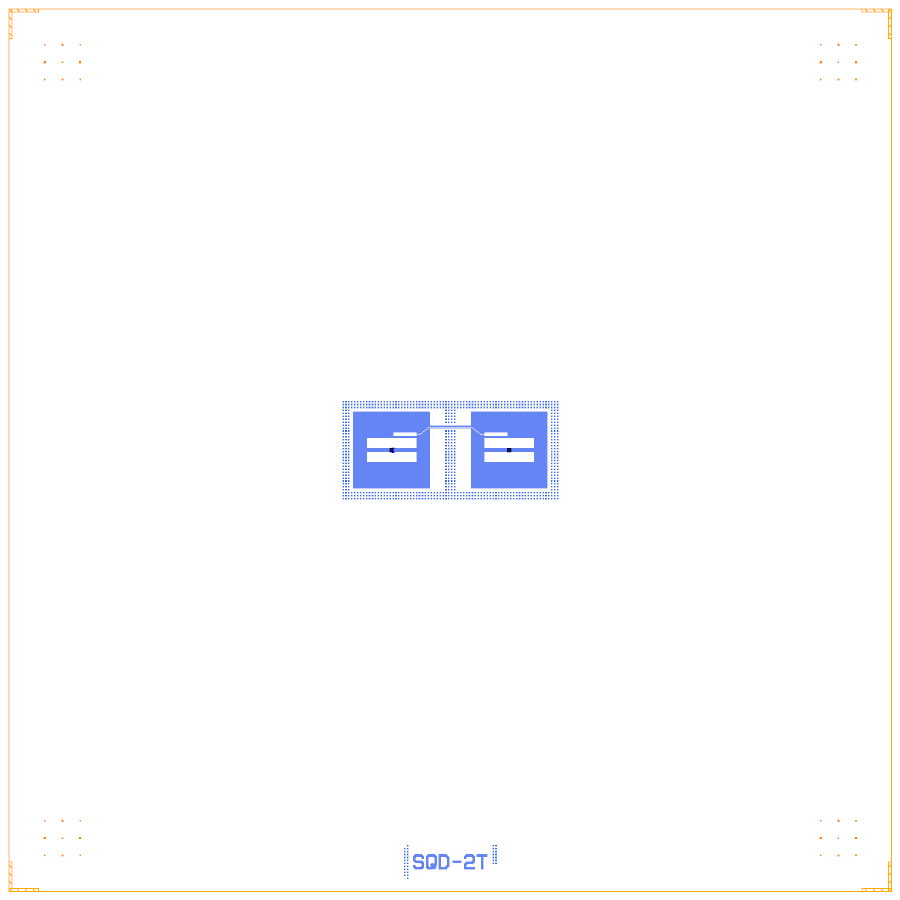

**On the chip so far:** 0 pads · 2 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/two_transmon/s8_chip.png')

In [9]:
d.sim_group("Q1Q2", ["Q1", "Q2", "COUPLER"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "two_transmon.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "s8_chip.png", size=(900, 900), width=360)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC
The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab; there must be none. **Warnings** are connectivity or geometry notes
to read (often by design). **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside
the PDK margins: flagged, never enforced — the rebuild keeps the source's choices. `pdk_report(d)` sums up the PDK
side: the cheese source, the content centre against the die centre, the junction types and the design warnings.
Expected here (from the v1 run): **no errors**; four `dangling_port` warnings, the `TransmonPocket` junction attachment points
`squid_a` / `squid_b` (the qubit cell draws its own junction, nothing is routed there); one PDK design warning,
`pdk_rn` on Q1: its junction sits exactly on the window's 50 kΩ edge (the source's detuning kept at the edge of
the window; flagged, not retuned).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes. A
`TransmonPocket` is a floating transmon — two pad nodes (`island1`, `island2`) with C to ground and between them,
the junction across them — plus one node per connection pad. The straight coupler joins the two `readout` pads
into one conductor, so Q1 and Q2 couple through C(Q1 pad → coupler) and C(coupler → Q2 pad) in series. No
resonators, feedlines or controls.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Q1 / Q2 ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(("Q1.", "Q2.")))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat finds the normal modes (frequencies, anharmonicities); QuTiP diagonalises the dressed Hamiltonian of both
qubits (f_q, α) and gives the static ZZ between them. No targets are stated in the source; the detuning comes
from the two junctions. Expected: f_q ≈ 7.0 / 7.7 GHz, α ≈ −350 / −325 MHz (small pads, small C_Σ), ZZ of a few
MHz (a strong direct coupling at 0.7 GHz detuning). From the v1 run: f_q 7.068 / 7.733 GHz, α −349 / −324 MHz, ZZ −3.88 MHz.

In [ ]:
res = simulate_lom(lb, d.design)
display(Markdown(modes_md(res)))
display(Markdown(summary_md(res)))
display(Markdown(zz_md(res)))

## LOM 2 · The LOM in a plot

The same results as a picture: (a) the two qubit modes (QuCat circles; filled markers are the QuTiP dressed values).
There is no resonator, so the dispersive-shift panel (b) stays empty; the coupling shows in the ZZ of LOM 1.

In [ ]:
plot_lom({"chip": res}, STEPS / "lom.png", title="two_transmon: LOM")

## LOM 3 · One change, by hand

Before the FEM, a design step by hand. A design change is a parameter change followed by a rebuild and a new LOM run. Here: give Q2 the PDK nominal
junction (R_n 45 kΩ, L_J 6.73 nH) instead of the 40 kΩ one. Q2's f_q drops by ≈ 0.35 GHz towards Q1; the
detuning (≈ 0.32 GHz) is then about one anharmonicity, where |11⟩ comes close to |02⟩, so the static ZZ grows by
an order of magnitude (≈ −4 → ≈ −56 MHz, from the v1 run). This is why the source detunes the pair. The change is made on a copy
(`design_copy`), so `two_transmon.json` keeps the source's detuning.

In [ ]:
d2 = design_copy(DESIGN)
JJP_N, JJ_N = trilayer_junction("metal:TransmonPocket", lj_nH=lj_from_rn(45e3))
d2["Q2"].set(junction=JJ_N, **JJP_N)
after = simulate_lom(d2.lom(), d2.design)
display(Markdown("**Q2 junction: R_n 40 → 45 kΩ**\n\n" + params_delta_md(res, after)))
display(Markdown("**ZZ before → after:**\n\n" + zz_md({"before": res, "after": after})))

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/sqdmetal/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (its margin), puts ports where lines leave the box, makes each junction a lumped port and writes one
job folder per group and analysis under `build/jobs/` (the group's own analyses: a Q3D C-matrix and an eigenmode /
EPR job). Simulation exports never have cheese; airbridges are dropped unless asked for. The table lists each job's
ports and C-matrix nets (named after the islands, pads and routes, so the results map back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line equivalent is
`qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/sqdmetal/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix of the sim group
jobs_eig = export_sims(DESIGN, analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says what the export
left out (this chip has no airbridges).

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "Q1Q2", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Simulate 2 · Component simulation: the Q3D C-matrix

The capacitance of the group `Q1Q2`: both qubits' pads and the coupler as named nets. The coupling between the qubits
is the small C from each pad to the coupler, the number the LOM estimates least well; each net is named after its LOM
node, so the matrix goes straight into the circuit (Results 3). `fem_stage` solves the job with `RUN_FEM`, else loads
its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The same box in HFSS eigenmode — the source's own analysis (a Palace eigenmode run, 2 modes from 5 GHz): each junction
is a lumped L_J ‖ C_J sheet; pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the two
junctions' energy participations into dressed frequencies, the anharmonicities and the cross-Kerr between the qubits
(their ZZ).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run: none here

A driven run computes S-parameters between ports, and this chip has none besides the junctions (no pads, no line),
as the source; so there is no driven job. The eigenmode run is the full-wave answer here.

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the first junction's participation p_J (Q1's), with the LOM's two qubit frequencies as dashed lines.
The table below lists the modes and the pyEPR values.

In [ ]:
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "Q2": res.params.get("Q2.f_q_GHz")}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: each qubit's mode is the one its own junction participates in most; f_q is
pyEPR's dressed frequency, α its self-Kerr, ZZ the cross-Kerr between the two qubit modes. `epr_values` expects a
readout per qubit; this chip has none, so a placeholder (`_`) collects any other mode and is dropped.

In [ ]:
fem_values = {}
if keep_eig["Q1Q2"]:
    vals = epr_values(keep_eig["Q1Q2"], {"Q1": "_", "Q2": "_"}, {"_": 0.0})   # "_": no readout on this chip
    fem_values = {k: v for k, v in vals.items() if not k.startswith("_.")}
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {v:.5g} |" for k, v in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q and α of both qubits and their ZZ "
          "from pyEPR.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrix:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name)
and the same LOM runs again, with its ZZ. **FEM directly:** the eigenmode (pyEPR) values of Results 2. The left column
is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill


def zz_of(r):
    """The Q1–Q2 static ZZ (MHz) of a LOM result, or None."""
    return next((z["zz_MHz"] for z in r.dressed.get("zz", []) if z["pair"] == "Q1-Q2"), None)


keys = ["Q1.f_q_GHz", "Q1.alpha_MHz", "Q2.f_q_GHz", "Q2.alpha_MHz"]
rows, on_fem = [], {}
if keep_q3d["Q1Q2"]:
    r_fem = simulate(fill(lb.model, DESIGN, keep_q3d["Q1Q2"]), max_modes=2)
    on_fem = r_fem.params
    rows += [(k, res.params.get(k), on_fem.get(k), "LOM on the Q3D C-matrix") for k in keys]
    rows.append(("Q1-Q2 ZZ (MHz)", zz_of(res), zz_of(r_fem), "LOM on the Q3D C-matrix"))
rows += [(k, res.params.get(k), fem_values[k], "eigenmode + pyEPR") for k in keys if k in fem_values]
if "Q1-Q2.zz_MHz" in fem_values:
    rows.append(("Q1-Q2 ZZ (MHz)", zz_of(res), fem_values["Q1-Q2.zz_MHz"], "eigenmode + pyEPR (cross-Kerr)"))
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts f_q and α of both qubits and their ZZ from the LOM "
          "next to the LOM on the Q3D C-matrix and the eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

The source states no targets. Q1's junction sits exactly on the 50 kΩ edge of the PDK window (Check 1 flags it,
`pdk_rn`), so this notebook's exercise target moves it just inside while keeping the source's detuning: **Q1 at
7.10 GHz**, ≈ 30 MHz above where the LOM puts it (from the v1 run: 7.068 GHz): L_J ≈ 7.42 nH, R_n ≈ 49.6 kΩ. There
is no readout, so `loop.feedback` (which tunes qubit–readout pairs) does not apply; the feedback is the transmon's
first-order rule f_q ∝ L_J^−1/2 (exact for √(8 E_J E_C); the −E_C offset is what the secant of Results 5 corrects),
kept inside the PDK window (`pdk_lj_bounds`). When a solve is kept, the LOM is first scaled by FEM / LOM of Q1
(`SCALE`): an L_J change leaves the geometry, and so the C-matrix, as it is, so the scale carries over to every
revision. The change is the LOM junction (`Q1.junction.Lj_nH`); to draw it, size the fingers with
`trilayer_junction("metal:TransmonPocket", lj_nH=...)`, as LOM 3 does. The target goes on a copy (`target_copy` → `build/two_transmon_target.json`); the revisions are
copies of it.

In [ ]:
F_T, F_TOL = 7.10, 0.005                         # the exercise target for Q1 and its tolerance (GHz)
DESIGN_T = target_copy(DESIGN, {"Q1": {"f_q_GHz": F_T}})
BOUND = pdk_lj_bounds(DESIGN)["Q1.junction.Lj_nH"]   # the L_J range of the 40–50 kΩ window
L0 = float(d.data["instances"]["Q1"]["junction"]["Lj_nH"])
f_lom = res.params.get("Q1.f_q_GHz")
f_fem = fem_values.get("Q1.f_q_GHz") or on_fem.get("Q1.f_q_GHz")
SCALE = f_fem / f_lom if f_fem else 1.0          # FEM / LOM at the drawn junction (1: the LOM alone)
L1 = min(max(rule_step(L0, SCALE * f_lom, F_T, -0.5), BOUND[0]), BOUND[1])
display(Markdown(f"**Q1:** now {SCALE * f_lom:.4f} GHz ({'FEM' if f_fem else 'LOM'}), target {F_T} ± {F_TOL} GHz → "
                 f"L_J {L0:.4f} → **{L1:.4f} nH** (R_n ∝ L_J: ≈ {50 * L1 / L0:.1f} kΩ; window "
                 f"{BOUND[0]:.3f}–{BOUND[1]:.3f} nH)"))

## Results 5 · Iterate to the target

The rule repeated (`rule_iterate`): revision k gets the L_J, its LOM runs (× `SCALE`), and the next step uses the
exponent of the last two points (a secant), until Q1 is within 5 MHz or `MAX_ITER` steps are made. No FEM solve per
revision: the geometry does not change. The ZZ of each revision is printed below the table: moving Q1 up narrows the
detuning, so the ZZ grows a little.

In [ ]:
ZZ = {0: zz_of(res)}


def f_q1_of(k, it):
    """Revision it: Q1's LOM junction at k nH (the geometry, and so the C-matrix, is unchanged)."""
    d2 = design_copy(DESIGN_T, f"_rev{it}")
    d2["Q1"].set(junction={**JJ_Q1, "Lj_nH": k})
    path = d2.save(Path("build") / f"two_transmon_rev{it}.json")
    r = simulate_lom(d2.lom(), d2.design)
    ZZ[it] = zz_of(r)
    return SCALE * r.params.get("Q1.f_q_GHz"), path


history = rule_iterate(f_q1_of, "Q1.f_q_GHz", "Q1.junction.Lj_nH", L0, F_T, F_TOL, -0.5, max_iter=MAX_ITER,
                       start=(SCALE * f_lom, DESIGN_T), bounds=BOUND)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("Q1–Q2 ZZ per iteration (MHz, LOM):", {k: (None if z is None else round(z, 3)) for k, z in ZZ.items()})

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `two_transmon.json` (saved in Design 8) is the whole design:
`qcc build examples/designs/sqdmetal/two_transmon.json` rebuilds `build/two_transmon.oas` + its sidecar, and the
KLayout plugin, `qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0
keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers 2/0 + 4/0 and
spacer 50/0 with the 51–53/0 dose gradient, and the frame (100/0, 1000/0, 1001/0). **Cheese:** the source has none,
so the PDK band stands — drawn in the build (`cheese_source` `build`), 3 rows of 5 µm squares round the 3/0
keep-outs, at least 4 µm clear of them. Corner rounding is fab-only (`FULL_FAB`); `qcc mask examples/designs/sqdmetal/two_transmon.json`
writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

Both pockets with the coupler; Q1's trilayer junction across the pad gap; the coupler landing on Q2's connection
pad; the die frame's south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and Q1's junction in
the **fab view** (the mask from Fab 1: base etch 1/0 with the PDK cheese band, the 3/0 keep-out, the junction
layers 2/0 + 4/0 + 50–53/0). In the layout snapshots the chip boundary 100/0 is drawn as an outline and the cheese
band (KQC's ground-grid layer) is visible; the fab view shows the mask itself.

In [ ]:
show_snapshot(d, OUT / "two_transmon.png", size=(1600, 1310))
show_snapshot(d, OUT / "two_transmon_jj.png", box=(X0 - 40, Y0 - 40, X0 + 40, Y0 + 40), width=300)
rx, ry = port_xy(d, "Q2.readout")
show_snapshot(d, OUT / "two_transmon_pad.png", box=(rx - 150, ry - 120, rx + 150, ry + 120), width=360)
show_snapshot(d, OUT / "two_transmon_frame.png", box=(-2650, -2850, -1750, -1950), size=(900, 900), width=300)
snap_file(Path("build") / "two_transmon_fab.oas", OUT / "two_transmon_fab_q1.png",
          box=(X0 - 400, Y0 - 400, X0 + 400, Y0 + 400), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | two `TransmonPocket`s with the source options and positions, the straight coupler between their facing connection pads, the detuning order Q1 < Q2, the eigenmode sim group |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame (source area centred); sapphire instead of silicon; Quantcore trilayer junctions at R_n 50 / 40 kΩ (f_q ≈ 7.0 / 7.7 GHz instead of the source's L_J 13 / 9 nH); the PDK cheese band in the mask (the source has none) |
| **pads** | none in the source (eigenmode model): nothing for the pad rule (100 µm) |
| **PDK design warnings** | `pdk_rn` on Q1 (exactly on the 50 kΩ edge of the window) |
| layout | built in segments (die, the two qubits, the coupler, the whole chip; no pads, readout or control lines); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (Q1 7.10 GHz, R_n just inside the window): the rule f_q ∝ L_J^−1/2 on Q1's LOM junction, iterated with a secant (LOM × FEM/LOM scale) |
| open | the FEM jobs (Q3D, eigenmode) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells |